# 21b — Publication figure: NMR data efficiency

Two panels compare **oxygen** and **silicon** test loss for three training strategies:

| Figure label | Trainable parameters | Source |
|:--|:--|:--|
| From scratch | Full network and NMR head, randomly initialised | Experiment 17 |
| Frozen backbone (head only) | NMR head, elemental scales and offsets | Experiment 21 |
| Final layer + head | Final interaction layer, NMR head, elemental scales and offsets | Experiment 19 |

The transfer strategies start from the same E/F-pretrained network. Each point uses the checkpoint
selected by minimum validation loss, evaluated on the same **150 held-out test structures**.
The figure contains no experiment numbers. This notebook recomputes plotted losses from saved
site-level predictions; it performs no model fitting, inference or checkpoint selection.

For element \(e\), the plotted loss is the **variance-normalised mean squared error**:
\[
L_e=\frac{1}{n_e\sigma_e^2}\sum_{i\in e}(\hat y_i-y_i)^2,
\qquad L_{\mathrm{balanced}}=\tfrac12(L_{\mathrm{Si}}+L_{\mathrm O}).
\]
The fixed training-derived standard deviations are \(\sigma_{\mathrm{Si}}=8.789599019755547\) ppm
and \(\sigma_{\mathrm O}=19.197689920683118\) ppm. Thus each panel shows one unweighted elemental
component of the original balanced loss, not RMSE or the combined two-element loss. Targets are
absolute isotropic DFT shieldings. Normalisation is not estimated from the test labels.


In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter

# Works when launched from the repository root or its experiments directory.
BASE = Path.cwd()
if not (BASE / '21-Test-DataEfficiency-data').is_dir():
    BASE = BASE / 'experiments'
SOURCE = BASE / '21-Test-DataEfficiency-data'
# The build script injects a staging path; interactive reruns use the directory below.
OUT = Path(globals().get('FIGURE_OUTPUT', BASE / '21b-NMR-DataEfficiency-figures'))
OUT.mkdir(parents=True, exist_ok=True)
source_files = ['metrics.csv', 'test-predictions.npz', 'checkpoint-audit.csv', 'manifest.json']
source_hashes = {name:hashlib.sha256((SOURCE/name).read_bytes()).hexdigest() for name in source_files}
metrics = pd.read_csv(SOURCE / 'metrics.csv')
manifest = json.loads((SOURCE / 'manifest.json').read_text())
audit = pd.read_csv(SOURCE / 'checkpoint-audit.csv')
EXPERIMENTS = [17, 21, 19]
SIZES = [10, 50, 100, 200, 800]
LABELS = {17:'From scratch', 21:'Frozen backbone (head only)', 19:'Final layer + head'}
STDS = manifest['loss_stds']
selected = metrics.query("split == 'test' and experiment in @EXPERIMENTS").copy()
assert len(selected) == 15
assert manifest['counts']['test']['structures'] == 150
assert not manifest['test_used_for_training_or_selection']
assert (selected.status == 'Early stopping').all()
assert selected.export_matches_checkpoint.all()
records = []
with np.load(SOURCE / 'test-predictions.npz') as saved:
    reference = saved['reference']
    atomic_numbers = saved['atomic_numbers']
    assert len(np.unique(saved['structure'])) == 150
    for _, run in selected.iterrows():
        balanced = 0.
        for element, z in [('O',8), ('Si',14)]:
            mask = atomic_numbers == z
            errors = saved[run.run_id][mask].astype(np.float64)-reference[mask]
            mse = np.mean(errors**2)
            loss = mse / STDS[element]**2
            np.testing.assert_allclose(np.sqrt(mse), run[element+'_rmse'], rtol=1e-12)
            balanced += loss/2
            records.append(dict(method=LABELS[int(run.experiment)], experiment=int(run.experiment),
                                element=element, n=int(run.n), test_loss=loss, mse_ppm2=mse,
                                rmse_ppm=np.sqrt(mse), sites=int(mask.sum()),
                                run_id=run.run_id, best_epoch=int(run.best_epoch)))
        np.testing.assert_allclose(balanced, run.loss, rtol=1e-12)
points = pd.DataFrame(records)
for exp in EXPERIMENTS:
    for element in ['O','Si']:
        assert points.query('experiment == @exp and element == @element').n.sort_values().tolist() == SIZES
points.to_csv(OUT / 'plotted-data.csv', index=False)
print('Verified 30 plotted values against saved site predictions and the original balanced loss.')
print('Test set: 150 structures; 14,400 oxygen and 7,200 silicon sites.')


Verified 30 plotted values against saved site predictions and the original balanced loss.
Test set: 150 structures; 14,400 oxygen and 7,200 silicon sites.


## Publication figure

Both axes are logarithmic and display values in their original units. Both panels share the same
y limits. Colours and line styles distinguish the methods; lines connect measured
points rather than a fitted scaling law. No uncertainty bands are shown because these are single-seed
training runs. The additional 50 validation structures are not counted on the x-axis.

The export is 8.8 inches wide, with an editable vector SVG and a 600 dpi PNG. Adjust the settings
below to match a journal's final column width and minimum font size.


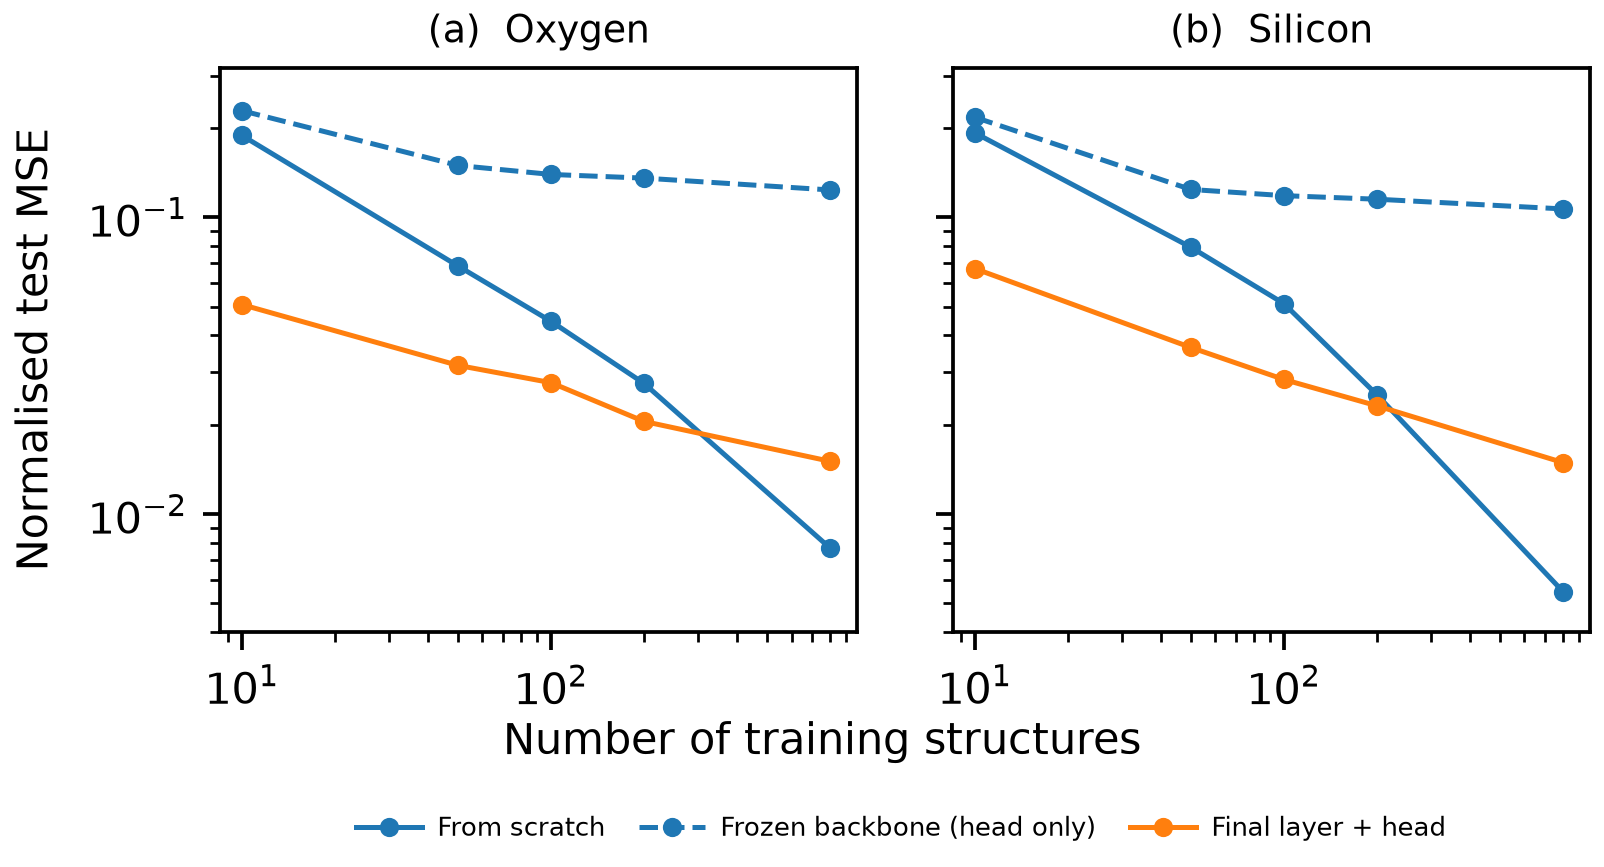

In [2]:
STYLE = {
    17: dict(color='#1f77b4', marker='o', linestyle='-'),
    21: dict(color='#1f77b4', marker='o', linestyle='--'),
    19: dict(color='#ff7f0e', marker='o', linestyle='-'),
}
rc = {
    'font.family':'DejaVu Sans', 'font.size':14,
    'axes.labelsize':17, 'axes.titlesize':15, 'axes.titleweight':'normal',
    'axes.edgecolor':'black', 'axes.linewidth':1.5,
    'axes.spines.top':True, 'axes.spines.right':True,
    'xtick.labelsize':17, 'ytick.labelsize':17,
    'xtick.color':'black', 'ytick.color':'black', 'text.color':'black',
    'axes.labelcolor':'black', 'legend.fontsize':10.5,
    'figure.facecolor':'white', 'axes.facecolor':'white',
    'svg.fonttype':'none', 'savefig.facecolor':'white',
}
with plt.rc_context(rc):
    fig, axes = plt.subplots(1, 2, figsize=(8.8,4.9), sharex=True, sharey=True)
    fig.subplots_adjust(left=.12, right=.985, top=.91, bottom=.27, wspace=.15)
    for ax, element, title in zip(axes, ['O','Si'], ['(a)  Oxygen', '(b)  Silicon']):
        for exp in EXPERIMENTS:
            d = points.query('experiment == @exp and element == @element').sort_values('n')
            ax.plot(d.n, d.test_loss, label=LABELS[exp], **STYLE[exp], linewidth=2,
                    markersize=7.7, markeredgewidth=0, zorder=3)
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlim(8.5,980)
        ax.set_ylim(.004,.32)
        for axis in (ax.xaxis, ax.yaxis):
            axis.set_major_locator(LogLocator(base=10, subs=(1.,)))
            axis.set_major_formatter(LogFormatterMathtext(base=10))
            axis.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10)*1., numticks=100))
            axis.set_minor_formatter(NullFormatter())
        ax.tick_params(which='major', direction='out', length=7, width=1.5, pad=6)
        ax.tick_params(which='minor', direction='out', length=4, width=1.1)
        ax.grid(False)
        ax.set_title(title, pad=10)
    axes[0].set_ylabel('Normalised test MSE', labelpad=12)
    fig.supxlabel('Number of training structures', y=.12, fontsize=17)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(.55,.005), ncol=3,
               frameon=False, handlelength=2.5, columnspacing=1.3, handletextpad=.6)
    for ext in ['svg','png']:
        fig.savefig(OUT / ('nmr-test-data-efficiency.'+ext), dpi=600, bbox_inches='tight', pad_inches=.08)
    plt.show()
    plt.close(fig)


## Suggested figure caption

**Data efficiency of NMR shielding prediction.** Test variance-normalised mean squared error for
(a) oxygen and (b) silicon as a function of the number of NMR training structures. Models are trained
from scratch, transferred from an energy/force model with the backbone frozen and only the NMR head
trained, or transferred with the final interaction layer and NMR head trained. The head includes
learned elemental scales and offsets. Each point uses the minimum-validation-loss checkpoint and
the same 150-structure test set. Normalisation uses fixed elemental variances from the 800-structure
training pool. The training subsets are nested, with one training seed per method and subset size;
an additional 50 validation structures are used throughout. Both axes are logarithmic; connecting
lines are guides to the eye.

## Data and provenance

The table below contains the plotted dimensionless losses. The CSV also retains unnormalised MSE,
RMSE, run identifiers and selected checkpoint epochs. `figure-provenance.json` fingerprints the source
data and describes the figure. Re-running this notebook refreshes only its own outputs.


In [3]:
print(points.pivot(index=['element','n'], columns='method', values='test_loss').to_string(float_format=lambda x:f'{x:.6f}'))
provenance = {
    'source_directory':str(SOURCE), 'source_sha256':source_hashes,
    'test_structures':150, 'validation_structures':50,
    'checkpoint_selection':'Minimum validation loss; no test-based selection',
    'element_loss':'Mean squared site error divided by fixed training-derived elemental variance',
    'balanced_loss':'0.5 * (silicon loss + oxygen loss)',
    'standard_deviations_ppm':STDS, 'methods':LABELS, 'training_sizes':SIZES,
    'seed':manifest['seed'], 'training_repetitions':1, 'panel_order':['O','Si'],
    'axis_scales':{'x':'log','y':'log'}, 'uncertainty_bands':False,
    'exports':['nmr-test-data-efficiency.svg','nmr-test-data-efficiency.png'],
    'raster_dpi':600, 'figure_inches':[8.8,4.9],
    'visual_style':'Boxed panels, no grid, circular markers, blue solid/dashed and orange solid, power-of-ten ticks with minor log ticks',
}
assert all(hashlib.sha256((SOURCE/name).read_bytes()).hexdigest()==digest for name,digest in source_hashes.items())
(OUT / 'figure-provenance.json').write_text(json.dumps(provenance,indent=2)+'\n')
print('\nSource files unchanged. Figure and plotted-data CSV saved in:', OUT.name)


method       Final layer + head  From scratch  Frozen backbone (head only)
element n                                                                 
O       10             0.050801      0.188863                     0.228877
        50             0.031691      0.068560                     0.149638
        100            0.027707      0.044617                     0.139522
        200            0.020509      0.027544                     0.135610
        800            0.015049      0.007671                     0.123696
Si      10             0.067192      0.192706                     0.217499
        50             0.036416      0.079290                     0.124152
        100            0.028404      0.051195                     0.118355
        200            0.023152      0.025222                     0.115116
        800            0.014902      0.005473                     0.106753

Source files unchanged. Figure and plotted-data CSV saved in: 21b-NMR-DataEfficiency-figures
